In [20]:
import random
import math
class Value:
    def __init__(self, data, _children=(), _op=''):
        self.data = data
        self._prev = set(_children)
        self._op = _op
        self.grad = 0
        self._backward = lambda : None

    def __repr__(self):
        return f"Value(data={self.data})"

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad
            other.grad += out.grad
        out._backward = _backward
        return out
    
    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def backward(self):
        self.grad = 1

        topo = []
        visited = set()

        def build_topo(v):
            if v not in visited:
                visited.add(v)
                for child in v._prev:
                    build_topo(child)
                topo.append(v)

        build_topo(self)

        for v in reversed(topo):
            v._backward()

    def tanh(self):
        out = Value(math.tanh(self.data), (self,), 'tanh')

        def _backward():
            self.grad += (1 - out.data**2) * out.grad

        out._backward = _backward
        return out

    def __neg__(self):
        out = Value(self.data * -1, (self,), '-')

        def _backward():
            self.grad += (-1 * out.grad)

        out._backward = _backward
        return out

    def __sub__(self, other):
        return self + (-other)

    def __pow__(self, exponent):
        out = Value(self.data ** exponent, (self,), '**')

        def _backward():
            self.grad += exponent * self.data ** (exponent - 1) * out.grad

        out._backward = _backward
        return out

    def __truediv__(self, other):
        return self * (other**-1)

    def __radd__(self, other):
        return self + other

    def __rmul__(self, other):
        return self * other

    def __rsub__(self, other):
        return other + (-self)

    def __rtruediv__(self, other):
        return other * (self**-1)
    
    
class Neuron:
    def __init__(self, nin):
        self.w = [Value(random.uniform(-1, 1)) for _ in range(nin)]
        self.b = Value(0)

    def __call__(self,x):
        act = sum((wi * xi for wi, xi in zip(self.w, x)), self.b)
        out = act.tanh()
        return out

    def parameters(self):
        return self.w + [self.b]


class Layer:
    def __init__(self, nin, nout):
        self.neurons = [Neuron(nin) for _ in range(nout)]

    def __call__(self, x):
        outputs = [neuron(x) for neuron in self.neurons]
        return outputs[0] if len(outputs) == 1 else outputs

    def parameters(self):
        return [
            parameter
            for neuron in self.neurons
            for parameter in neuron.parameters()
        ]

neuron = Neuron(2)

x = [Value(2.0), Value(3.0)]
output = neuron(x)

layer = Layer(2, 3)

x = [Value(2), Value(3)]
outputs = layer(x)

print("Outputs:", outputs)
print("Number of outputs:", len(outputs))

loss = sum(outputs, Value(0))
loss.backward()


print("First neuron's weight gradients:",
      [w.grad for w in layer.neurons[0].w])


print("Output:", output.data)
print("Weights:", neuron.w)
print("Bias:", neuron.b)


class MLP:
    def __init__(self, nin, nouts):
        sizes = [nin] + nouts
        self.layers = [
            Layer(sizes[i], sizes[i+1])
            for i in range(len(nouts))
        ]

    def __call__(self, x):
        for layer in self.layers:
            x = layer(x)
        return x

    def parameters(self):
        return [
            parameter
            for layer in self.layers
            for parameter in layer.parameters()
        ]


# Create the training dataset
training_data = [
    ([2.0, 3.0, -1.0], 1.0),
    ([3.0, -1.0, 0.5], -1.0),
    ([-1.0, -2.0, 2.0], 1.0),
    ([1.0, 1.0, -1.0], -1.0),
]

# Create the network
network = MLP(3, [4, 4, 1])

# Training settings
learning_rate = 0.05
epochs = 100

for epoch in range(epochs):

    # Calculate predictions and loss
    losses = []

    for inputs, target_value in training_data:
        x = [Value(value) for value in inputs]
        prediction = network(x)
        target = Value(target_value)

        loss = (prediction - target) ** 2
        losses.append(loss)

    total_loss = sum(losses, Value(0))

    # Reset gradients before backpropagation
    for parameter in network.parameters():
        parameter.grad = 0

    # Calculate gradients
    total_loss.backward()

    # Update weights and biases
    for parameter in network.parameters():
        parameter.data -= learning_rate * parameter.grad

    if epoch % 10 == 0:
        print(f"Epoch {epoch}: Loss = {total_loss.data:.4f}")

Outputs: [Value(data=-0.7526718954825297), Value(data=-0.15219541016174332), Value(data=0.29326263380044665)]
Number of outputs: 3
First neuron's weight gradients: [0.8669700355014718, 1.3004550532522077]
Output: 0.09654548749734802
Weights: [Value(data=-0.31920079880712904), Value(data=0.24508291393350667)]
Bias: Value(data=0)
Epoch 0: Loss = 4.3927
Epoch 10: Loss = 0.4283
Epoch 20: Loss = 0.0682
Epoch 30: Loss = 0.0349
Epoch 40: Loss = 0.0229
Epoch 50: Loss = 0.0168
Epoch 60: Loss = 0.0132
Epoch 70: Loss = 0.0109
Epoch 80: Loss = 0.0092
Epoch 90: Loss = 0.0079


In [39]:
output.backward()

print("Output gradient:", output.grad)
print("Weight gradients:", [w.grad for w in neuron.w])
print("Bias gradient:", neuron.b.grad)

Output gradient: 1
Weight gradients: [8.562130231841905, 7.338968770150204]
Bias gradient: 2.4463229233834016


In [19]:
x = Value(0.5)
y = x.tanh()
y.backward()

print(y.data)
print(x.grad)

0.46211715726000974
0.7864477329659274


In [9]:
a = Value(2)
b = Value(3)

d = a * b
d.grad = 1

d._backward()

print(a.grad)
print(b.grad)

3
2


In [11]:
a = Value(2)
b = Value(-3)
c = Value(8)

d = a * b + c

d.grad = 1
d._backward()

print(a.grad, b.grad, c.grad)

0 0 1


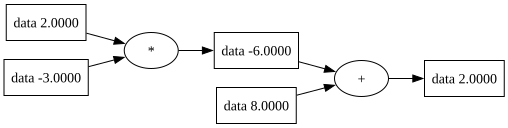

In [3]:
from graphviz import Digraph

def trace(root):
 # builds a set of all nodes and edges in a graph
 nodes, edges = set(), set()
 def build(v):
  if v not in nodes:
   nodes.add(v)
   for child in v._prev:
    edges.add((child, v))
    build(child)
 build(root)
 return nodes, edges

def draw_dot(root):
 dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'}) # LR = left to right
 
 nodes, edges = trace(root)
 for n in nodes:
  uid = str(id(n))
  # for any value in the graph, create a rectangular ('record') node for it
  dot.node(name = uid, label = "{ data %.4f }" % (n.data, ), shape='record')
  if n._op:
   # if this value is a result of some operation, create an op node for it
   dot.node(name = uid + n._op, label = n._op)
   # and connect this node to it
   dot.edge(uid + n._op, uid)
   
 for n1, n2 in edges:
  # connect n1 to the op node of n2
  dot.edge(str(id(n1)), str(id(n2)) + n2._op)
  
 return dot


draw_dot(d)
